In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

ROOT_DIR = Path.cwd().parent

sys.path.append(str(ROOT_DIR))

print("Project root:", ROOT_DIR)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
# Thư viện	Công việc
# sys	Tương tác với môi trường Python
# Path	Xử lý đường dẫn file, thư mục
# numpy	Tính toán ma trận, vector
# pandas	Đọc và xử lý dữ liệu dạng bảng
# matplotlib	Vẽ biểu đồ

Project root: C:\Users\PC\ML-Projects\Linear_Regression
NumPy: 2.4.6
Pandas: 3.1.1


In [3]:
DATA_PATH = Path("../data/house_predict.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("dataset not found")
df = pd.read_csv(DATA_PATH)
print("load data")
print(df.shape)

load data
(1460, 81)


In [4]:
from sklearn.model_selection import train_test_split

# Lấy các feature dạng số, bỏ Id và target
X = df.select_dtypes(include=np.number).drop(
    columns=["Id", "SalePrice"],
    errors="ignore"
)

y = df["SalePrice"].to_numpy().reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
# 1. Import train_test_split
# from sklearn.model_selection import train_test_split
# Ta sử dụng một công cụ có sẵn của Scikit-learn để chia dữ liệu.
# Lưu ý: chúng ta chỉ dùng Scikit-learn để hỗ trợ chia dữ liệu, không dùng nó để huấn luyện Linear Regression.
# 2. Tạo X
# X = df.select_dtypes(include=np.number)
# select_dtypes() lọc các cột theo kiểu dữ liệu.
# include=np.number nghĩa là chỉ lấy các cột có kiểu dữ liệu số.
# Sau đó:
# .drop(columns=["Id", "SalePrice"], errors="ignore")
# Loại bỏ hai cột:
# - Id: mã định danh căn nhà, không dùng làm feature trong phiên bản này.
# - SalePrice: chính là kết quả chúng ta muốn dự đoán.
# Tại sao phải loại SalePrice?
# Vì nếu đưa giá nhà thực tế vào đầu vào, model sẽ nhìn thấy đáp án trước khi dự đoán. Đây là một dạng Data Leakage.
# 3. Tạo y
# y = df["SalePrice"].to_numpy().reshape(-1, 1)
# Đây là biến mục tiêu (Target).Ý nghĩa các tham số:
# - test_size=0.2: giữ lại 20% dữ liệu để kiểm tra.
# - random_state=42: cố định cách chia để có thể tái lập kết quả.
# Tại sao không dùng toàn bộ 1.460 dòng để train?
# Vì nếu model vừa học vừa kiểm tra trên cùng dữ liệu, ta không biết nó có thực sự dự đoán tốt trên những căn nhà chưa từng gặp hay không.

Train: (1168, 36)
Test: (292, 36)


In [5]:
# Impute missing values
X_median = X_train.median()# Tính median của từng cột trong tập train.

X_train = X_train.fillna(X_median)# fillna() thay thế các giá trị bị thiếu bằng median tương ứng của từng feature.
X_test = X_test.fillna(X_median)

# Convert to numpy
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()

# Standardization
X_mean = X_train.mean(axis=0)# mean(axis=0): tính trung bình từng cột.
X_std = X_train.std(axis=0)#std(axis=0): tính độ lệch chuẩn từng cột.

X_std[X_std == 0] = 1

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Scale target
y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train - y_mean) / y_std

print("Preprocessing completed!")
print("X train:", X_train_scaled.shape)
print("X test:", X_test_scaled.shape)
# Tại sao không tính median trên toàn bộ dataset?
# Vì nếu tính trên cả test, thông tin từ tập kiểm tra đã tham gia vào quá trình preprocessing.
# Đây là một dạng Data Leakage.
# Pandas DataFrame thuận tiện cho xử lý dữ liệu dạng bảng.
# NumPy array thuận tiện cho các phép toán ma trận.
# Tương tự X, chúng ta chuẩn hóa giá nhà.
# Điểm quan trọng: chỉ chuẩn hóa y_train, không dùng y_test để tính mean và std.
# Khi dự đoán, ta sẽ chuyển kết quả về USD bằng:
# y_original = y^_scaled x y_std + y_mean
# Đến đây dữ liệu đã sẵn sàng để đưa vào thuật toán.

Preprocessing completed!
X train: (1168, 36)
X test: (292, 36)


In [6]:
from src.models.linear_regression import LinearRegressionGD

model = LinearRegressionGD(
    learning_rate=0.01,
    epochs=5000
)

model.fit(X_train_scaled, y_train_scaled)# Đưa dữ liệu train vào thuật toán.

print("Training completed!")
print("Final loss:", model.loss_history[-1])# [-1] lấy phần tử cuối cùng của list, tức loss tại epoch cuối cùng.
# 1. Import class
# from src.models.linear_regression import LinearRegressionGD
# Lấy class từ file riêng trong src/.
# 2. Tạo object
# model = LinearRegressionGD(...)
# Lúc này mới chỉ khởi tạo model, chưa học gì cả.
# 3. Train
# Đưa dữ liệu train vào thuật toán.
# Sau 5.000 epoch, model có các trọng số đã được cập nhật.
# 4. Kiểm tra Loss
# model.loss_history[-1]

Training completed!
Final loss: 0.19287823435902013


In [7]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict
y_pred_scaled = model.predict(X_test_scaled)

# Convert predictions về USD
y_pred = y_pred_scaled * y_std + y_mean

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== LINEAR REGRESSION EVALUATION =====")
print(f"MAE:  ${mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2:   {r2:.4f}")
# 1. Predict trên test
# y_pred_scaled = model.predict(X_test_scaled)
# Model nhận 292 căn nhà chưa từng dùng để train.
# Nó sử dụng theta đã học để tính ra 292 mức giá dự đoán.
# 2. Chuyển về đơn vị USD
# y_pred = y_pred_scaled * y_std + y_mean
# Lúc train, chúng ta đã chuẩn hóa giá nhà.
# Vì vậy, dự đoán hiện tại vẫn nằm trên thang đo chuẩn hóa.
# Ta cần khôi phục về USD để kết quả dễ hiểu và sử dụng trong thực tế.
# 3. Các chỉ số đánh giá
# Metric	Ý nghĩa	Đơn vị
# MAE	Sai số tuyệt đối trung bình	USD
# MSE	Bình phương sai số trung bình	USD²
# RMSE	Căn bậc hai của MSE	USD
# R²	Khả năng giải thích biến thiên của target	Không đơn vị

===== LINEAR REGRESSION EVALUATION =====
MAE:  $22,978.91
MSE:  1,357,165,229.08
RMSE: $36,839.72
R2:   0.8231


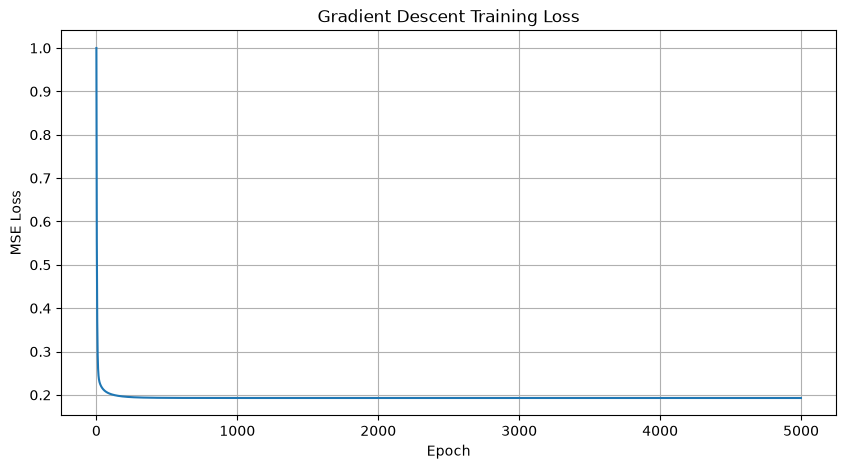

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(model.loss_history)

plt.title("Gradient Descent Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.grid()
plt.show()
# Biểu đồ giúp trả lời:
# - Loss có giảm không?
# - Model có hội tụ không?
# - Loss có dao động bất thường không?
# - Learning rate có quá lớn không?
# Nếu loss giảm rồi ổn định, đó là dấu hiệu thuật toán đang hội tụ.
# Nếu loss tăng liên tục hoặc thành NaN, cần kiểm tra learning rate, dữ liệu và phép tính.

In [9]:
from sklearn.model_selection import train_test_split

# Features
X = df.select_dtypes(include=np.number).drop(
    columns=["Id", "SalePrice"],
    errors="ignore"
)

# Target
y = df["SalePrice"].to_numpy().reshape(-1, 1)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X:", X.shape)
print("y:", y.shape)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X: (1460, 36)
y: (1460, 1)
X_train: (1168, 36)
X_test: (292, 36)
y_train: (1168, 1)
y_test: (292, 1)
